# XGBoost: feature sets and hyperparameters

XGBoost models of survival on the 891 train passengers, varying which features go in and how the trees are grown. Test passengers are not used for scoring.

**Features.**

- **Core**: class (`Pclass`), title (Mr, Mrs, Miss, Master, Rare), sex, age, has a cabin recorded (`HasCabin`), deck. Deck is the first letter of the cabin, else the deck of a ticket-mate with a cabin (see `add_deck.py`). Age and deck are left missing where unknown; XGBoost learns which way missing values go.
- **SibSp, Parch**: siblings and spouses aboard, parents and children aboard.
- **Female-relative survival** (`fem_rel_survival`): the share of the passenger's known female relatives in train who survived. Relatives are the mother, plus sisters and daughters for female passengers.
- **Family survival** (`family_survival`): the share of all the passenger's known relatives in train who survived.
- **Ticket-mate survival** (`ticket_survival`): the share of other passengers on the same ticket who survived, leaving out the passenger's own family (anyone listed in `Relatives` or with the same `FamilyId`).
- **Fare, port**: fare and port of embarkation. Not on the original list; added in one set as a check.

The three survival features are blank where no relative or ticket-mate is in train. A passenger's own outcome never feeds their own feature.

**Holdouts.** Train is split into 4 parts of about 223 passengers, keeping each family and each ticket group whole and each part's survival rate close to the overall 38%. Parts 1, 2 and 3 are the holdouts: each model is trained on the other 75% and scored on that part, so the three holdouts never overlap. Part 4 is never a holdout. Because a passenger's relatives and ticket-mates are always on the same side of the split, the survival features of training rows only use training outcomes.

**Scores.** Accuracy (predicting survival where the predicted probability is 0.5 or more) is the Kaggle metric. Log loss, which also rewards well-judged probabilities, is shown alongside: it is less noisy on small samples. One passenger is 0.45 points of accuracy on one holdout, and 0.15 points on the average of the three.

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
from joblib import Parallel, delayed
from IPython.display import display, Markdown
from sklearn.metrics import accuracy_score, log_loss, roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold

SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, GREEN = "#2a78d6", "#eb6834", "#3a9b5c"
plt.rcParams.update({
    "font.family": ["Helvetica Neue", "Arial", "DejaVu Sans"], "font.size": 9.5,
    "text.color": INK, "axes.edgecolor": AXIS, "axes.labelcolor": INK2,
    "xtick.color": INK2, "ytick.color": INK2,
    "axes.facecolor": SURFACE, "figure.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110,
})
def clean(ax, grid="y"):
    ax.grid(axis=grid, color=GRID, linewidth=0.6); ax.tick_params(length=0)
    for sp in ax.spines.values():
        sp.set_visible(False)

def find_data():
    from pathlib import Path
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / "data" / "complete_data.csv").exists():
            return p / "data" / "complete_data.csv"
c = pd.read_csv(find_data())

# Core features
t = c["Name"].str.extract(r",\s*([^.]+)\.", expand=False).str.strip().replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
c["Title"] = t.where(t.isin(["Mr", "Mrs", "Miss", "Master"]), "Rare")
c["SexF"] = (c["Sex"] == "female").astype(int)
c["HasCabin"] = c["Cabin"].notna().astype(int)
for col in ["Title", "Deck", "Embarked"]:
    c[col] = pd.Categorical(c[col], categories=sorted(c[col].dropna().unique()))

# Survival features, from train outcomes only
def parse(s):
    out = []
    if isinstance(s, str):
        for part in s.split(";"):
            role, ids = part.strip().split(" ", 1)
            out += [(role, int(i)) for i in ids.split(",")]
    return out
rel = dict(zip(c["PassengerId"], c["Relatives"].map(parse)))
sex = dict(zip(c["PassengerId"], c["Sex"]))
fam = dict(zip(c["PassengerId"], c["FamilyId"]))
tick = dict(zip(c["PassengerId"], c["Ticket"]))
on_ticket = c.groupby("Ticket")["PassengerId"].apply(list).to_dict()
is_tr = c["Dataset"] == "train"
surv = dict(zip(c.loc[is_tr, "PassengerId"], c.loc[is_tr, "Survived"]))
def share(ids, pid):
    v = [surv[o] for o in ids if o in surv and o != pid]
    return float(np.mean(v)) if v else np.nan
def fem_rel(pid):
    return share([o for role, o in rel[pid] if sex[o] == "female"
                  and (role == "parent" or (sex[pid] == "female" and role in ("sibling", "child")))], pid)
def fam_all(pid):
    return share([o for _, o in rel[pid]], pid)
def ticket_nonfam(pid):
    rels, f = {o for _, o in rel[pid]}, fam[pid]
    return share([o for o in on_ticket[tick[pid]] if o not in rels and not (pd.notna(f) and fam[o] == f)], pid)
c["fem_rel_survival"] = c["PassengerId"].map(fem_rel)
c["family_survival"] = c["PassengerId"].map(fam_all)
c["ticket_survival"] = c["PassengerId"].map(ticket_nonfam)

# Groups that must stay on one side of a split: linked by ticket, FamilyId or a listed relative
parent = {p: p for p in c["PassengerId"]}
def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]; x = parent[x]
    return x
def link(ids):
    ids = list(ids)
    for i in ids[1:]:
        parent[find(i)] = find(ids[0])
for _, ids in c.groupby("Ticket")["PassengerId"]:
    link(ids)
for _, ids in c.dropna(subset=["FamilyId"]).groupby("FamilyId")["PassengerId"]:
    link(ids)
for p, rs in rel.items():
    link([p] + [o for _, o in rs])
c["Group"] = c["PassengerId"].map(find)

tr = c[is_tr].reset_index(drop=True)
y = tr["Survived"].astype(int).values

CORE = ["Pclass", "Title", "SexF", "Age", "HasCabin", "Deck"]
SP = ["SibSp", "Parch"]
SETS = {
    "Core": CORE,
    "Core + SibSp, Parch": CORE + SP,
    "+ female-relative survival": CORE + SP + ["fem_rel_survival"],
    "+ family survival": CORE + SP + ["family_survival"],
    "+ ticket-mate survival": CORE + SP + ["ticket_survival"],
    "+ female-relative and family": CORE + SP + ["fem_rel_survival", "family_survival"],
    "+ all three survival": CORE + SP + ["fem_rel_survival", "family_survival", "ticket_survival"],
    "+ all three, fare, port": CORE + SP + ["fem_rel_survival", "family_survival", "ticket_survival", "Fare", "Embarked"],
}

# Worked examples from the feature spec
chk = c.loc[c["PassengerId"].isin([945, 439, 1032]), ["PassengerId", "Name", "Dataset", "fem_rel_survival", "family_survival", "ticket_survival"]]
chk["Expected female-relative"] = chk["PassengerId"].map({945: 1.0, 439: np.nan, 1032: 0.0})
chk["Expected family"] = chk["PassengerId"].map({945: 0.5, 439: 2 / 3, 1032: 0.0})
ok = all(np.allclose(chk[a].values, chk[b].values, equal_nan=True) for a, b in
         [("fem_rel_survival", "Expected female-relative"), ("family_survival", "Expected family")])
display(chk.round(3).style.hide(axis="index").format(precision=3, na_rep="blank"))
cov = tr[["fem_rel_survival", "family_survival", "ticket_survival"]].notna().sum()
display(Markdown(
    f"Worked examples {'match' if ok else '**do not match**'} the spec. "
    f"Train passengers with a value: female-relative survival {cov['fem_rel_survival']}, "
    f"family survival {cov['family_survival']}, ticket-mate survival {cov['ticket_survival']}, of {len(tr)}."
))

PassengerId,Name,Dataset,fem_rel_survival,family_survival,ticket_survival,Expected female-relative,Expected family
439,"Fortune, Mr. Mark",train,blank,0.667,blank,blank,0.667
945,"Fortune, Miss. Ethel Flora",test,1.000,0.500,blank,1.000,0.500
1032,"Goodwin, Miss. Jessie Allis",test,0.000,0.000,blank,0.000,0.000


Worked examples match the spec. Train passengers with a value: female-relative survival 131, family survival 281, ticket-mate survival 109, of 891.

## Findings

- **Features matter far more than hyperparameters.** Moving from the worst to the best feature set improves median log loss from 0.447 to 0.400. Across the 400 random settings, most of the gap between good and typical hyperparameters is about 0.02.
- **Female-relative survival is the feature that counts.** Added to Core + SibSp and Parch, it lifts median accuracy from 81.8% to 84.1% and beats that set in 94% of the 400 settings. Family survival adds 1.5 points. Combining the two is best on log loss (best in 40% of settings, average rank 1.9 of 8).
- **Ticket-mate survival and fare plus port add nothing.** Ticket-mate survival alone ties Core + SibSp and Parch (better in 49% of settings). Adding it, fare and port to the other two survival features leaves accuracy unchanged.
- **SibSp and Parch help.** Core alone is 1.9 points worse on median accuracy, and worse on log loss in 94% of settings.
- **Hyperparameters: learn enough, but not too much.** Learning rate × number of trees is the setting that matters most: below 2 the model underfits badly (median log loss 0.48). Between 5 and 50 it levels off. Trees 2 to 6 deep do equally well; depth 1 and depth 8 are worse. The other hyperparameters move log loss by about 0.01.
- **Use about 85% as the expected accuracy, not the best score.** The best tuned models score 85.2% to 85.5%, but that is the best of 400 tries on the same three holdouts. Holdout 3 scores about 3 points below holdouts 1 and 2 for every feature set, which is larger than most of the differences between hyperparameter settings.

## The three holdouts

In [2]:
sgk = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=0)
parts = list(sgk.split(tr, y, tr["Group"]))
SPLITS = parts[:3]
hold = [set(b) for _, b in SPLITS]
assert not (hold[0] & hold[1]) and not (hold[0] & hold[2]) and not (hold[1] & hold[2])

# Leakage check: no training row's survival feature may use a holdout passenger's outcome
pos = dict(zip(tr["PassengerId"], range(len(tr))))
links = {p: ({o for _, o in rel[p]} | set(on_ticket[tick[p]])) - {p} for p in tr["PassengerId"]}
leaks = [sum(1 for p in tr["PassengerId"].iloc[a] for o in links[p] if o in pos and pos[o] in hold[k])
         for k, (a, b) in enumerate(SPLITS)]
rows = []
for k, (a, b) in enumerate(SPLITS):
    rows.append({"Holdout": k + 1, "Train passengers": len(a), "Holdout passengers": len(b),
                 "Holdout survival": f"{y[b].mean():.0%}", "Families or ticket groups held out": tr["Group"].iloc[b].nunique(),
                 "Training rows using a holdout outcome": leaks[k]})
display(pd.DataFrame(rows).style.hide(axis="index"))
never = len(parts[3][1])
display(Markdown(
    f"The holdouts share no passengers. {never} passengers (part 4) are always in training and never scored. "
    f"Largest linked group: {tr['Group'].value_counts().iloc[0]} train passengers."
))

Holdout,Train passengers,Holdout passengers,Holdout survival,Families or ticket groups held out,Training rows using a holdout outcome
1,669,222,38%,165,0
2,668,223,39%,163,0
3,668,223,39%,162,0


The holdouts share no passengers. 223 passengers (part 4) are always in training and never scored. Largest linked group: 7 train passengers.

## The experiments

Two runs, each repeated for all 8 feature sets and all 3 holdouts:

- **One at a time.** Start from a baseline (depth 3, learning rate 0.05, 300 trees, min_child_weight 1, gamma 0, subsample 0.8, colsample_bytree 0.8, lambda 1, alpha 0) and move one hyperparameter at a time across a range, holding the rest at the baseline. This shows the effect of each hyperparameter on its own.
- **Random search.** 400 random combinations of all nine hyperparameters. This shows which combinations work best together, and whether the best feature set changes with the hyperparameters.

No early stopping: it would have to watch the holdout, which would leak it into the model. The number of trees is a hyperparameter instead.

In [3]:
BASE = dict(max_depth=3, learning_rate=0.05, n_estimators=300, min_child_weight=1.0, gamma=0.0,
            subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0, reg_alpha=0.0)
SWEEP = {
    "max_depth": [1, 2, 3, 4, 5, 6, 8],
    "learning_rate": [0.01, 0.02, 0.05, 0.1, 0.2, 0.3],
    "n_estimators": [50, 100, 200, 300, 500, 1000],
    "min_child_weight": [0.5, 1, 2, 4, 8, 16],
    "gamma": [0, 0.25, 0.5, 1, 2, 5],
    "subsample": [0.5, 0.6, 0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.4, 0.5, 0.6, 0.8, 1.0],
    "reg_lambda": [0, 0.3, 1, 3, 10, 30],
    "reg_alpha": [0, 0.1, 0.3, 1, 3],
}
configs = [("baseline", None, None, dict(BASE))]
for p, vals in SWEEP.items():
    for v in vals:
        if v != BASE[p]:
            configs.append((f"sweep {p}={v}", p, v, {**BASE, p: v}))
rng = np.random.default_rng(0)
for i in range(400):
    configs.append((f"random {i:03d}", "random", None, dict(
        max_depth=int(rng.integers(1, 9)),
        learning_rate=float(np.exp(rng.uniform(np.log(0.005), np.log(0.3)))),
        n_estimators=int(rng.choice([50, 100, 200, 300, 500, 800, 1200])),
        min_child_weight=float(np.exp(rng.uniform(np.log(0.5), np.log(16)))),
        gamma=0.0 if rng.random() < 0.4 else float(np.exp(rng.uniform(np.log(0.05), np.log(5)))),
        subsample=float(rng.uniform(0.5, 1.0)),
        colsample_bytree=float(rng.uniform(0.4, 1.0)),
        reg_lambda=float(np.exp(rng.uniform(np.log(0.1), np.log(30)))),
        reg_alpha=0.0 if rng.random() < 0.5 else float(np.exp(rng.uniform(np.log(0.01), np.log(5)))),
    )))

def fit_score(cfg_name, fs, k, hp):
    a, b = SPLITS[k]
    cols = SETS[fs]
    m = xgb.XGBClassifier(**hp, objective="binary:logistic", tree_method="hist", enable_categorical=True,
                          n_jobs=1, random_state=0)
    m.fit(tr.loc[a, cols], y[a])
    p = m.predict_proba(tr.loc[b, cols])[:, 1]
    return dict(config=cfg_name, features=fs, holdout=k + 1, acc=accuracy_score(y[b], p >= 0.5),
                ll=log_loss(y[b], p), auc=roc_auc_score(y[b], p))

jobs = [(n, fs, k, hp) for n, _, _, hp in configs for fs in SETS for k in range(3)]
R = pd.DataFrame(Parallel(n_jobs=-1, prefer="threads", batch_size=64)(delayed(fit_score)(*j) for j in jobs))
meta = pd.DataFrame([{"config": n, "param": p, "value": v, **hp} for n, p, v, hp in configs])
R = R.merge(meta, on="config")
from pathlib import Path
R.to_csv(Path.cwd() / "xgb_v1_results.csv", index=False)
M = R.groupby(["config", "features"], sort=False).agg(acc=("acc", "mean"), ll=("ll", "mean"), auc=("auc", "mean"),
                                                      acc_min=("acc", "min"), acc_max=("acc", "max")).reset_index()
M = M.merge(meta, on="config")
FS = list(SETS)
display(Markdown(f"{len(configs)} hyperparameter settings × {len(SETS)} feature sets × 3 holdouts = {len(R):,} models trained. "
                 f"Every row is saved to `models/xgb_v1/xgb_v1_results.csv`."))

445 hyperparameter settings × 8 feature sets × 3 holdouts = 10,680 models trained. Every row is saved to `models/xgb_v1/xgb_v1_results.csv`.

## Which feature set is best?

Each feature set scored three ways: at the baseline hyperparameters, as the median over the 400 random settings (typical performance, not tuned), and at its own best random setting (tuned, so optimistic: picking the best of 400 on the same holdouts flatters it by an unknown amount).

,Baseline accuracy,Baseline log loss,"Median accuracy, 400 settings",Median log loss,Best accuracy,Best: per holdout
Features,,,,,,
Core,80.1%,0.445,79.8%,0.447,82.0%,"86.0, 86.5, 77.6"
"Core + SibSp, Parch",82.3%,0.433,81.8%,0.435,83.4%,"82.9, 82.5, 80.7"
+ female-relative survival,84.3%,0.388,84.1%,0.406,85.3%,"83.3, 87.4, 83.0"
+ family survival,83.4%,0.406,83.4%,0.411,84.6%,"87.4, 87.0, 81.6"
+ ticket-mate survival,82.8%,0.427,81.9%,0.435,83.5%,"86.0, 86.1, 78.5"
+ female-relative and family,83.2%,0.389,84.0%,0.400,85.2%,"86.9, 87.0, 81.6"
+ all three survival,84.4%,0.387,84.0%,0.400,85.5%,"86.9, 87.4, 82.1"
"+ all three, fare, port",83.5%,0.397,84.0%,0.406,85.5%,"85.6, 88.3, 82.5"


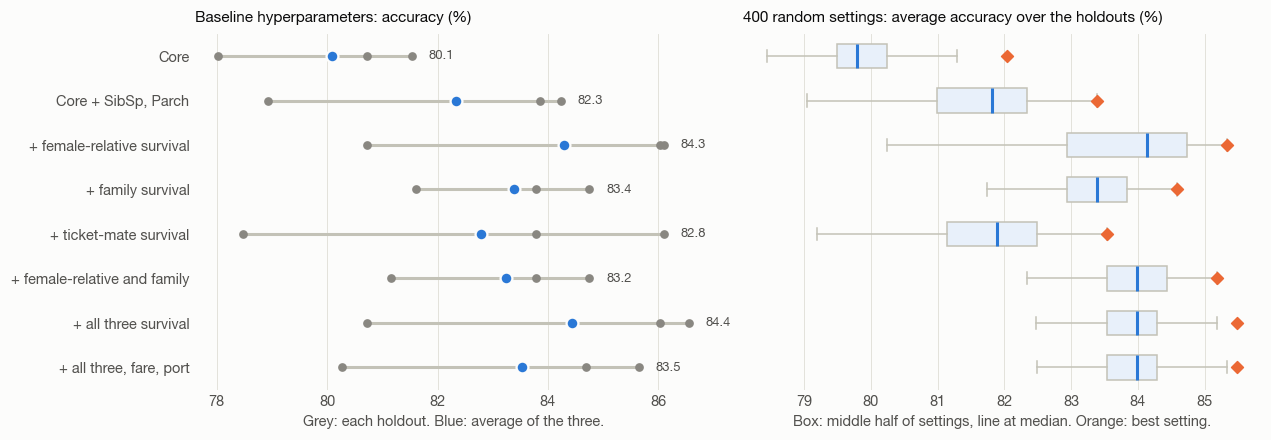

**Does the best feature set change with the hyperparameters?** For each of the 400 random settings, the 8 feature sets ranked by log loss:

,Best log loss in this share of settings,Average rank (1 = best)
Features,,
Core,0%,7.8
"Core + SibSp, Parch",0%,6.4
+ female-relative survival,20%,3.3
+ family survival,4%,4.3
+ ticket-mate survival,0%,6.5
+ female-relative and family,40%,1.9
+ all three survival,23%,2.3
"+ all three, fare, port",12%,3.5


In [4]:
rand = M[M["param"] == "random"]
base = M[M["config"] == "baseline"].set_index("features")
med = rand.groupby("features")[["acc", "ll"]].median()
best = rand.sort_values(["acc", "ll"], ascending=[False, True]).groupby("features").head(1).set_index("features")
tbl = pd.DataFrame({
    "Baseline accuracy": (100 * base["acc"]).map("{:.1f}%".format),
    "Baseline log loss": base["ll"].map("{:.3f}".format),
    "Median accuracy, 400 settings": (100 * med["acc"]).map("{:.1f}%".format),
    "Median log loss": med["ll"].map("{:.3f}".format),
    "Best accuracy": (100 * best["acc"]).map("{:.1f}%".format),
    "Best: per holdout": [", ".join(f"{100 * v:.1f}" for v in R[(R["config"] == best.loc[f, "config"]) & (R["features"] == f)]["acc"]) for f in best.index],
}).reindex(FS)
tbl.index.name = "Features"
display(tbl)

# Chart: accuracy per holdout at the baseline, and distribution over random settings
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2), sharey=True, gridspec_kw={"wspace": 0.06})
yy = np.arange(len(FS))
ax = axes[0]
for i, f in enumerate(FS):
    r = R[(R["config"] == "baseline") & (R["features"] == f)]["acc"] * 100
    ax.plot([r.min(), r.max()], [i, i], color=AXIS, linewidth=2, zorder=2)
    ax.scatter(r, [i] * 3, s=22, color=MUTED, zorder=3)
    ax.scatter([r.mean()], [i], s=60, color=BLUE, edgecolor=SURFACE, linewidth=1.5, zorder=4)
    ax.text(r.max() + 0.3, i, f"{r.mean():.1f}", va="center", fontsize=8.5, color=INK2)
clean(ax, "x")
ax.set_title("Baseline hyperparameters: accuracy (%)", loc="left", fontsize=10, pad=8)
ax.set_xlabel("Grey: each holdout. Blue: average of the three.")
ax = axes[1]
data = [rand[rand["features"] == f]["acc"] * 100 for f in FS]
bp = ax.boxplot(data, positions=yy, vert=False, widths=0.55, patch_artist=True, showfliers=False,
                medianprops=dict(color=BLUE, linewidth=2), boxprops=dict(facecolor="#e8f0fa", edgecolor=AXIS),
                whiskerprops=dict(color=AXIS), capprops=dict(color=AXIS))
for i, f in enumerate(FS):
    ax.scatter([best.loc[f, "acc"] * 100], [i], marker="D", s=30, color=ORANGE, zorder=4)
clean(ax, "x")
axes[0].set_yticks(yy, FS); axes[0].set_ylim(len(FS) - 0.5, -0.5)
ax.set_title("400 random settings: average accuracy over the holdouts (%)", loc="left", fontsize=10, pad=8)
ax.set_xlabel("Box: middle half of settings, line at median. Orange: best setting.")
plt.show()

# Does the winner depend on the hyperparameters?
piv = rand.pivot(index="config", columns="features", values="ll")[FS]
rank = piv.rank(axis=1)
w = pd.DataFrame({"Best log loss in this share of settings": (rank.eq(1).mean() * 100).map("{:.0f}%".format),
                  "Average rank (1 = best)": rank.mean().map("{:.1f}".format)}).reindex(FS)
w.index.name = "Features"
display(Markdown("**Does the best feature set change with the hyperparameters?** For each of the 400 random settings, the 8 feature sets ranked by log loss:"))
display(w)

The order is the same at the baseline, at the median and at the best setting: the sets with female-relative survival lead, Core trails. Each survival set beats Core + SibSp and Parch on log loss in 95% to 99% of the 400 settings, so the gain does not depend on the hyperparameters. The top four sets are within 0.5 points of median accuracy of each other, which is about 3 passengers across the three holdouts. On accuracy alone they cannot be separated.

## Each hyperparameter on its own

Average accuracy and log loss over the three holdouts as one hyperparameter moves and the rest stay at the baseline (marked with a dashed line). Three feature sets shown: Core, Core + SibSp and Parch, and all three survival features added.

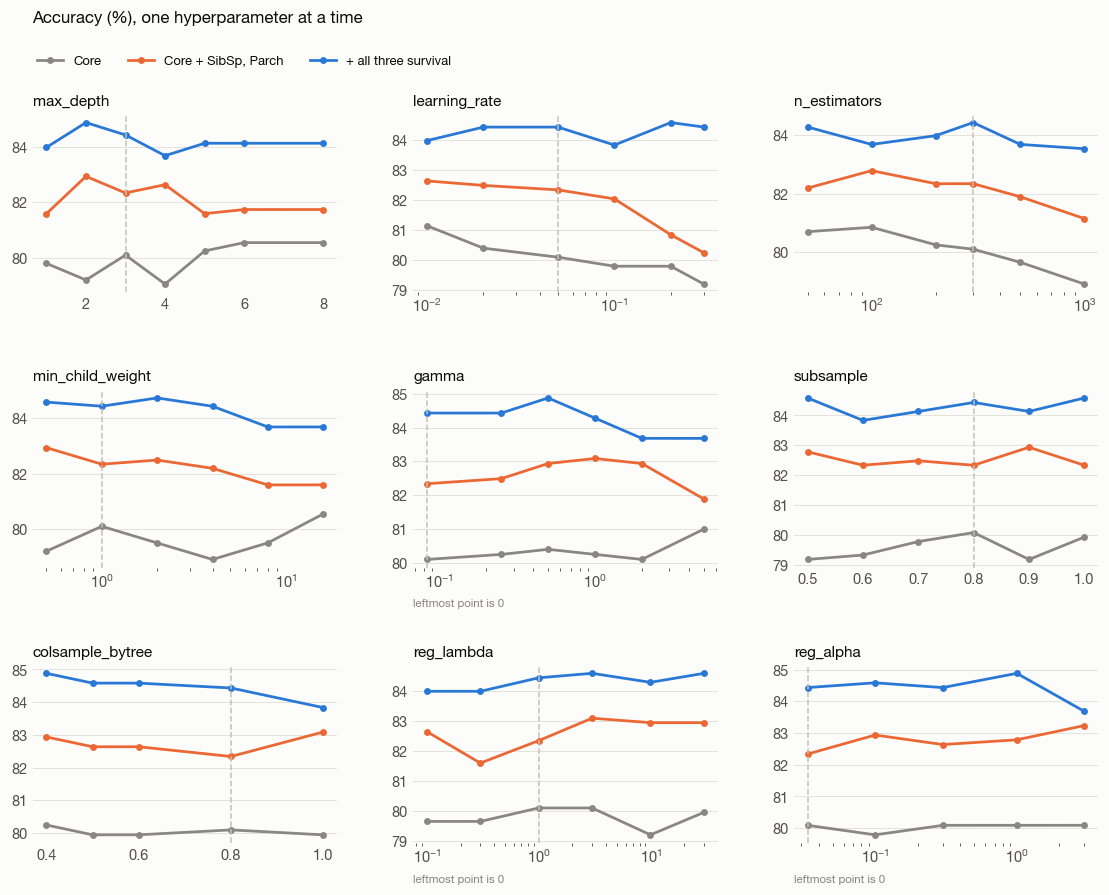

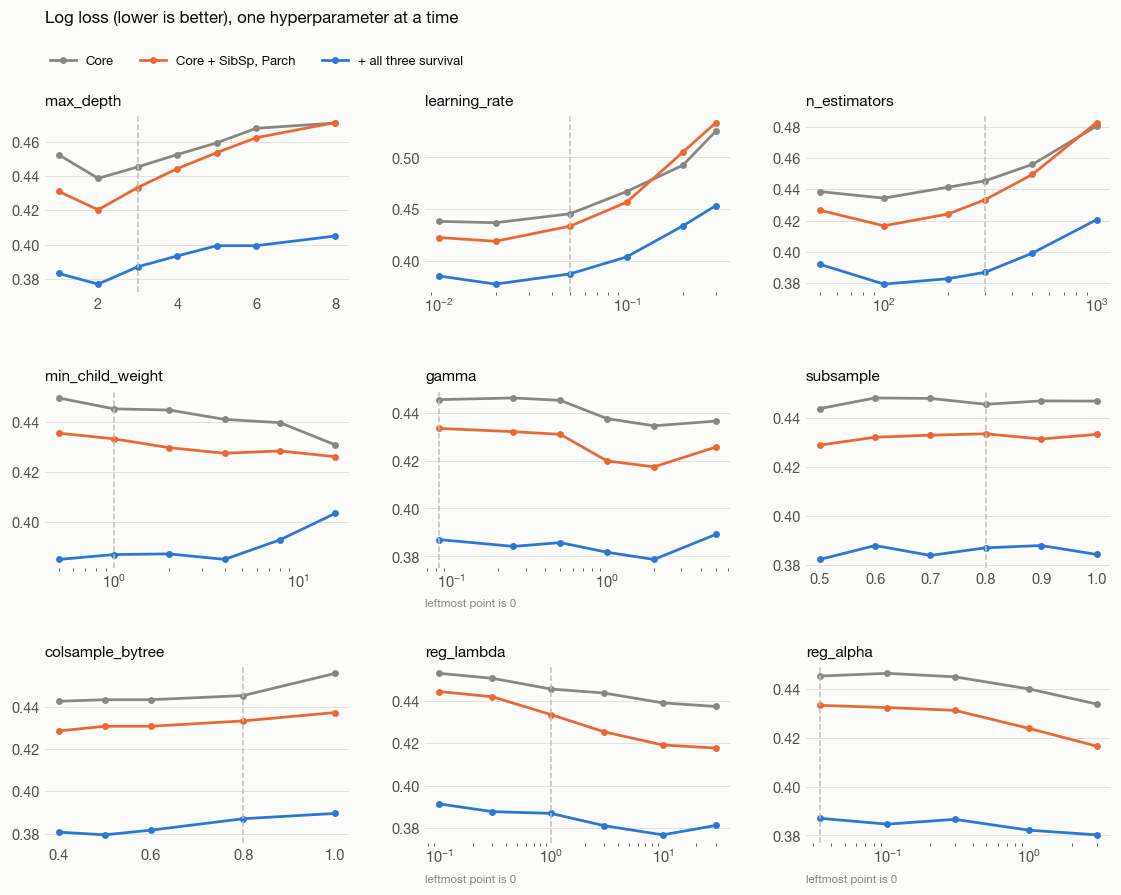

In [5]:
SHOW = {"Core": MUTED, "Core + SibSp, Parch": ORANGE, "+ all three survival": BLUE}
def sweep_rows(p, f):
    s = M[(M["param"] == p) & (M["features"] == f)][["value", "acc", "ll"]]
    b = M[(M["config"] == "baseline") & (M["features"] == f)][["acc", "ll"]].assign(value=BASE[p])
    return pd.concat([s, b]).astype(float).sort_values("value")
LOG = {"learning_rate", "n_estimators", "min_child_weight", "reg_lambda"}
for metric, lab in [("acc", "Accuracy (%)"), ("ll", "Log loss (lower is better)")]:
    fig, axes = plt.subplots(3, 3, figsize=(12.5, 8.6), gridspec_kw={"hspace": 0.55, "wspace": 0.25})
    for ax, p in zip(axes.flat, SWEEP):
        for f, col in SHOW.items():
            s = sweep_rows(p, f)
            x = s["value"].values
            if p in ("gamma", "reg_lambda", "reg_alpha"):
                x = np.where(x == 0, np.nan, x)
            v = s[metric].values * (100 if metric == "acc" else 1)
            if p in LOG | {"gamma", "reg_alpha"}:
                ax.set_xscale("log")
            xs = s["value"].values
            if p in ("gamma", "reg_lambda", "reg_alpha"):
                pos0 = sorted(set(xs[xs > 0]))[0] / 3
                xs = np.where(xs == 0, pos0, xs)
            ax.plot(xs, v, color=col, linewidth=1.8, marker="o", markersize=3.5, label=f)
        ax.axvline(BASE[p] if BASE[p] > 0 else sorted(set(s["value"][s["value"] > 0]))[0] / 3,
                   color=AXIS, linestyle="--", linewidth=1)
        clean(ax)
        ax.set_title(p, loc="left", fontsize=10, pad=6)
        if p in ("gamma", "reg_lambda", "reg_alpha"):
            ax.text(0.0, -0.22, "leftmost point is 0", transform=ax.transAxes, fontsize=7.5, color=MUTED)
    h, l = axes[0, 0].get_legend_handles_labels()
    fig.legend(h, l, frameon=False, fontsize=8.5, loc="upper left", ncol=3, bbox_to_anchor=(0.12, 0.955))
    fig.suptitle(lab + ", one hyperparameter at a time", x=0.125, ha="left", fontsize=11, y=0.99)
    plt.show()

With the survival features in (blue), most of the curves are nearly flat: no single hyperparameter moves accuracy by more than about 1 point from the baseline. Log loss shows the pattern more clearly. It gets worse as trees grow deeper than 2, as the learning rate rises above 0.05 and as trees go past 300, all signs of overfitting. Stronger L2 regularisation (lambda 3 to 10) and a small gamma (around 1 to 2) help a little. Core and Core + SibSp and Parch are more sensitive to these settings than the set with survival features.

## Random search: the best settings

The 15 best model and feature-set pairs from the random search, by average accuracy over the three holdouts, with log loss to separate ties. Several feature sets and settings are within one or two passengers of each other.

Features,Accuracy,Worst holdout,Best holdout,Log loss,depth,eta,trees,min_child_wt,gamma,subsample,colsample,lambda,alpha
+ all three survival,85.5,82.1,87.4,0.373,6,0.043,800,1.491,1.927,0.939,0.437,0.111,0.000
"+ all three, fare, port",85.5,82.5,88.3,0.386,1,0.182,200,0.676,1.894,0.900,0.593,9.405,0.000
+ female-relative survival,85.3,81.6,87.4,0.374,2,0.062,100,1.006,0.000,0.782,0.868,0.294,0.084
+ female-relative survival,85.3,81.6,87.4,0.375,4,0.096,100,0.947,3.111,0.884,0.932,0.561,0.000
+ female-relative survival,85.3,81.6,87.4,0.393,5,0.132,500,4.890,3.018,0.717,0.548,8.595,0.023
+ female-relative survival,85.3,81.6,87.9,0.386,6,0.005,500,2.163,1.685,0.670,0.961,1.276,0.000
+ female-relative survival,85.3,81.6,87.9,0.400,5,0.121,800,6.376,2.516,0.715,0.604,16.540,0.000
+ female-relative survival,85.3,82.1,87.9,0.389,1,0.099,100,3.468,0.000,0.674,0.405,0.583,0.000
+ female-relative survival,85.3,82.1,87.9,0.390,1,0.017,1200,2.470,0.190,0.610,0.430,10.958,0.022
+ female-relative survival,85.3,82.1,87.9,0.394,5,0.135,800,2.288,4.065,0.902,0.669,13.934,0.000


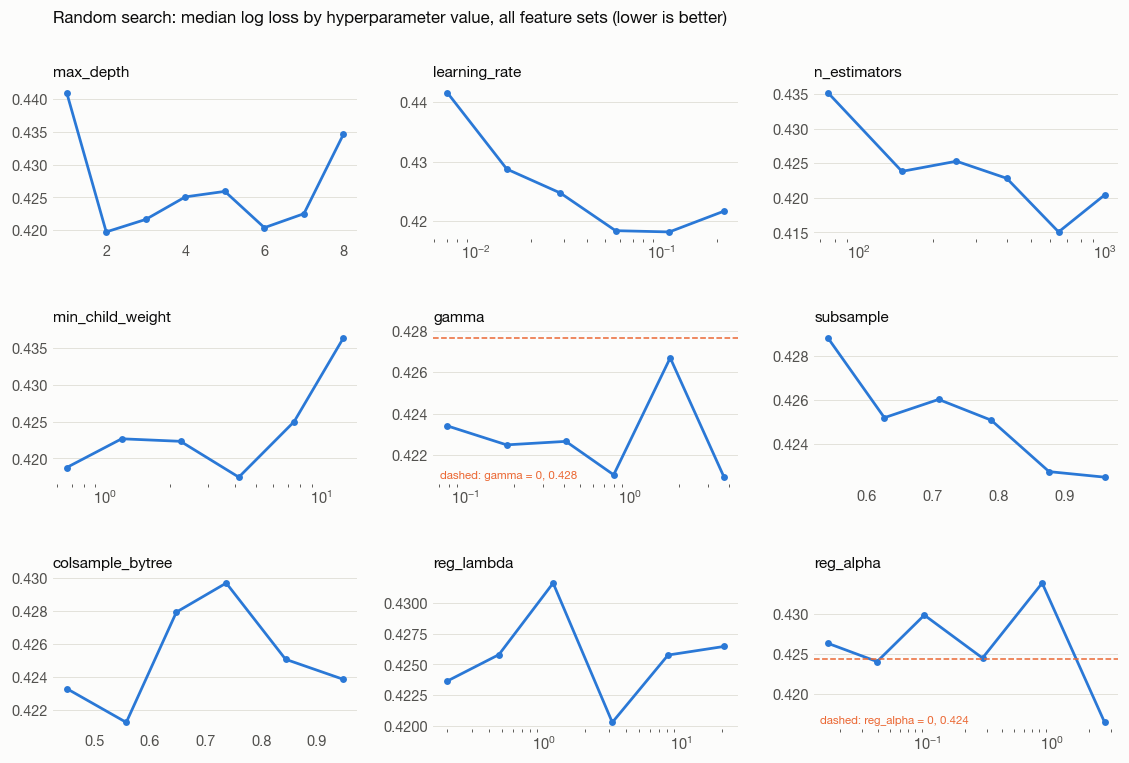

Each point is the median log loss of the random settings in that band of the hyperparameter, whatever the others were set to. A flat line means the hyperparameter matters little on its own; a dip shows the range that works.

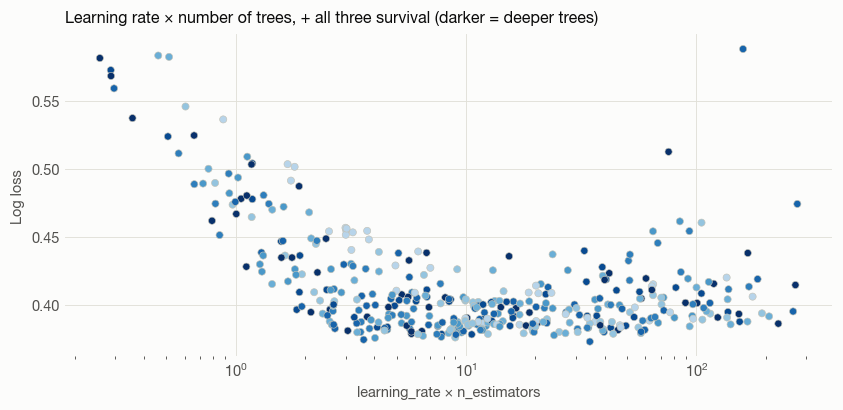

Median log loss by band of learning_rate × n_estimators: 0 to 2: 0.478 (59 settings), 2 to 5: 0.403 (73 settings), 5 to 10: 0.390 (65 settings), 10 to 20: 0.390 (63 settings), 20 to 50: 0.392 (66 settings), 50 to 2000: 0.401 (74 settings).

In [6]:
top = rand.sort_values(["acc", "ll"], ascending=[False, True]).head(15)
show = top[["features", "acc", "acc_min", "acc_max", "ll", "max_depth", "learning_rate", "n_estimators",
            "min_child_weight", "gamma", "subsample", "colsample_bytree", "reg_lambda", "reg_alpha"]].copy()
for col in ["acc", "acc_min", "acc_max"]:
    show[col] = (100 * show[col]).map("{:.1f}".format)
show = show.rename(columns={"features": "Features", "acc": "Accuracy", "acc_min": "Worst holdout", "acc_max": "Best holdout",
                            "ll": "Log loss", "max_depth": "depth", "learning_rate": "eta", "n_estimators": "trees",
                            "min_child_weight": "min_child_wt", "colsample_bytree": "colsample", "reg_lambda": "lambda",
                            "reg_alpha": "alpha"})
display(show.style.hide(axis="index").format(precision=3))

# Which settings the best models share: compare the top 10% of random settings with all of them, per hyperparameter
fig, axes = plt.subplots(3, 3, figsize=(12.5, 7.6), gridspec_kw={"hspace": 0.6, "wspace": 0.25})
pool = rand.copy()
cut = pool["ll"].quantile(0.10)
for ax, p in zip(axes.flat, SWEEP):
    v = pool[p].astype(float)
    if p in LOG | {"gamma", "reg_alpha"}:
        bins = np.unique(np.quantile(v[v > 0], np.linspace(0, 1, 7)))
        ax.set_xscale("log")
    else:
        bins = np.unique(np.quantile(v, np.linspace(0, 1, 7))) if p != "max_depth" else np.arange(0.5, 9.5, 1)
    g = pd.cut(v, bins, include_lowest=True)
    mm = pool.groupby(g, observed=True)["ll"].median()
    centres = [iv.mid if p != "max_depth" else round(iv.mid) for iv in mm.index]
    ax.plot(centres, mm.values, color=BLUE, marker="o", markersize=3.5, linewidth=1.8)
    if p in ("gamma", "reg_alpha"):
        z = pool[v == 0]["ll"].median()
        ax.axhline(z, color=ORANGE, linewidth=1, linestyle="--")
        ax.text(0.02, 0.04, f"dashed: {p} = 0, {z:.3f}", transform=ax.transAxes, fontsize=7.5, color=ORANGE)
    clean(ax)
    ax.set_title(p, loc="left", fontsize=10, pad=6)
fig.suptitle("Random search: median log loss by hyperparameter value, all feature sets (lower is better)", x=0.125, ha="left", fontsize=11, y=0.97)
plt.show()
display(Markdown("Each point is the median log loss of the random settings in that band of the hyperparameter, whatever the others were set to. "
                 "A flat line means the hyperparameter matters little on its own; a dip shows the range that works."))

# Learning rate and number of trees work as a pair: their product is the total amount learned
s = rand[rand["features"] == "+ all three survival"].copy()
s["lr_x_trees"] = s["learning_rate"] * s["n_estimators"]
fig, ax = plt.subplots(figsize=(9, 3.8))
sc = ax.scatter(s["lr_x_trees"], s["ll"], c=s["max_depth"], cmap="Blues", vmin=-2, vmax=8, s=22, edgecolor=AXIS, linewidth=0.4, zorder=3)
ax.set_xscale("log"); clean(ax, "both")
ax.set_xlabel("learning_rate × n_estimators"); ax.set_ylabel("Log loss")
ax.set_title("Learning rate × number of trees, + all three survival (darker = deeper trees)", loc="left", fontsize=10.5, pad=8)
plt.show()
bands = s.groupby(pd.cut(s["lr_x_trees"], [0, 2, 5, 10, 20, 50, 2000]), observed=True)["ll"].agg(["median", "size"])
display(Markdown("Median log loss by band of learning_rate × n_estimators: " +
                 ", ".join(f"{iv.left:g} to {iv.right:g}: {r['median']:.3f} ({int(r['size'])} settings)" for iv, r in bands.iterrows()) + "."))

The top 15 is dominated by sets with female-relative survival, at a range of different settings: depth 2 to 6 with few trees, or many trees with a low learning rate. Many different hyperparameter settings reach the same score. Across all settings, the clearest pattern is the product of learning rate and number of trees: too little learning costs far more than too much. The best 10% of settings for the + all three survival set use a lower min_child_weight (median 1.2, against 2.9 for all settings) and otherwise look like the rest.

## What the best model relies on

The best random setting for the full feature set (all three survival features, fare and port), retrained on each 75% and scored by permutation importance on its holdout: shuffle one feature, and measure how much log loss rises. Averaged over the three holdouts and 20 shuffles each.

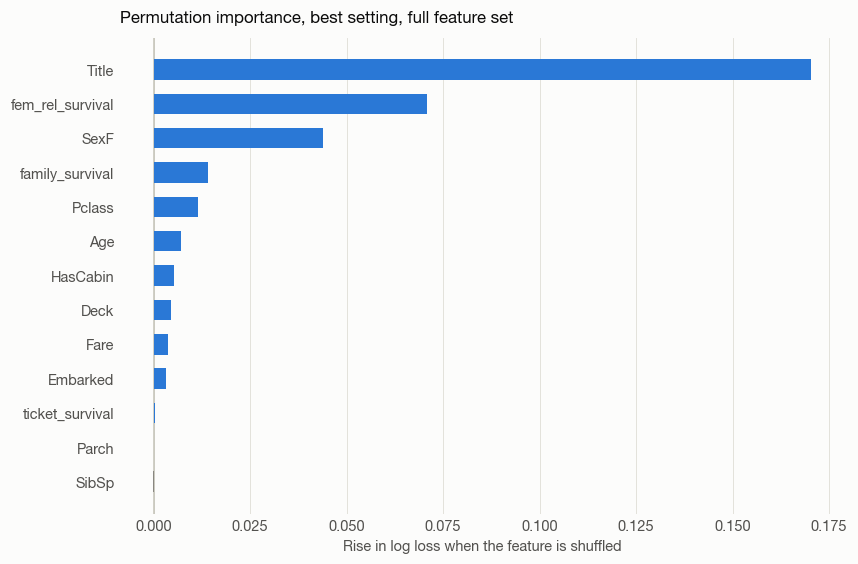

Settings used: max_depth 1, learning_rate 0.182, n_estimators 200, min_child_weight 0.676, gamma 1.89, subsample 0.9, colsample_bytree 0.593, reg_lambda 9.41, reg_alpha 0.

In [7]:
f = "+ all three, fare, port"
cfg = best.loc[f, "config"]
hp = meta.set_index("config").loc[cfg, list(BASE)].to_dict()
hp["max_depth"], hp["n_estimators"] = int(hp["max_depth"]), int(hp["n_estimators"])
cols = SETS[f]
rs_ = np.random.default_rng(1)
out = {c_: [] for c_ in cols}
for a, b in SPLITS:
    m = xgb.XGBClassifier(**hp, tree_method="hist", enable_categorical=True, n_jobs=4, random_state=0).fit(tr.loc[a, cols], y[a])
    Xb = tr.loc[b, cols].reset_index(drop=True)
    l0 = log_loss(y[b], m.predict_proba(Xb)[:, 1])
    for c_ in cols:
        for _ in range(20):
            Xp = Xb.copy(); Xp[c_] = Xp[c_].sample(frac=1, random_state=int(rs_.integers(1e9))).values
            out[c_].append(log_loss(y[b], m.predict_proba(Xp)[:, 1]) - l0)
pi = pd.Series({k: np.mean(v) for k, v in out.items()}).sort_values()
fig, ax = plt.subplots(figsize=(8.5, 0.34 * len(pi) + 1.2))
ax.barh(range(len(pi)), pi.values, height=0.6, color=[BLUE if v > 0 else MUTED for v in pi.values], zorder=3)
ax.set_yticks(range(len(pi)), pi.index)
ax.axvline(0, color=AXIS, linewidth=1); clean(ax, "x")
ax.set_xlabel("Rise in log loss when the feature is shuffled")
ax.set_title("Permutation importance, best setting, full feature set", loc="left", fontsize=11, pad=10)
plt.show()
display(Markdown("Settings used: " + ", ".join(f"{k} {v:.3g}" for k, v in hp.items()) + "."))

Title carries the most information. It holds sex and age group together: Master marks a boy. Female-relative survival is second, ahead of sex, and family survival is fourth. Ticket-mate survival, SibSp and Parch contribute almost nothing once the survival features are in. SibSp and Parch helped the Core set because they partly stand in for family, which the survival features now cover directly.